In [ ]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('diabetic_data.csv') #veri yükleme

In [ ]:
df.replace('?', np.nan, inplace=True) #? işaretlerini NaN'a (boş veriye) çeviriyoruz.

In [ ]:
df.head()

In [ ]:
display(df.describe()) #Eksik verilerin (NaN) sayısını görme

In [ ]:
print(df.isnull().sum()) #hangi sütunda ne kadar boşluk olduğunu tespit ettik.

In [ ]:
df.drop(['weight', 'payer_code', 'medical_specialty', 'encounter_id', 'patient_nbr'], axis=1, inplace=True) #aşırı eksik olan verileri sildik.

In [ ]:
df.info()

In [ ]:
race_mode = df['race'].mode()[0] #Race sütununda en çok tekrar eden değeri bulduk.

df.fillna({"race":race_mode}, inplace=True) #race sütunundaki boş değerleri, en çok tekrar edenle doldurduk.

In [ ]:
print(df.isnull().sum()) #boş olanları tekrar listeledik.

In [ ]:
df['total_visits'] = df['number_outpatient'] + df['number_emergency'] + df['number_inpatient'] #3 benzer özelliği teke düşürdük.

In [ ]:
df.drop(['number_outpatient', 'number_emergency', 'number_inpatient'], axis=1, inplace=True) #eski sütunlar silindi.

In [ ]:
df = pd.get_dummies(df, columns=['gender','race']) #gender ve race sütunlarındaki her bir kategoriyi ayrı bir sütun yapıp 1 ve 0 ile kodladık.
df.head()

In [ ]:
# readmitted sütununu 0, 1 ve 2 olarak etiketledik.
df['readmitted'] = df['readmitted'].astype(str)
df['readmitted'] = df['readmitted'].replace('NO', 0)
df['readmitted'] = df['readmitted'].replace('>30', 1)
df['readmitted'] = df['readmitted'].replace('<30', 2)

In [ ]:
df.drop(['max_glu_serum', 'A1Cresult'], axis=1, inplace=True) #çok fazla eksik veriye sahip olan 2 sütun silindi.

In [ ]:
df.dropna(subset=['diag_1', 'diag_2', 'diag_3'], inplace=True) #eksik veri bulunan satırlar silindi.

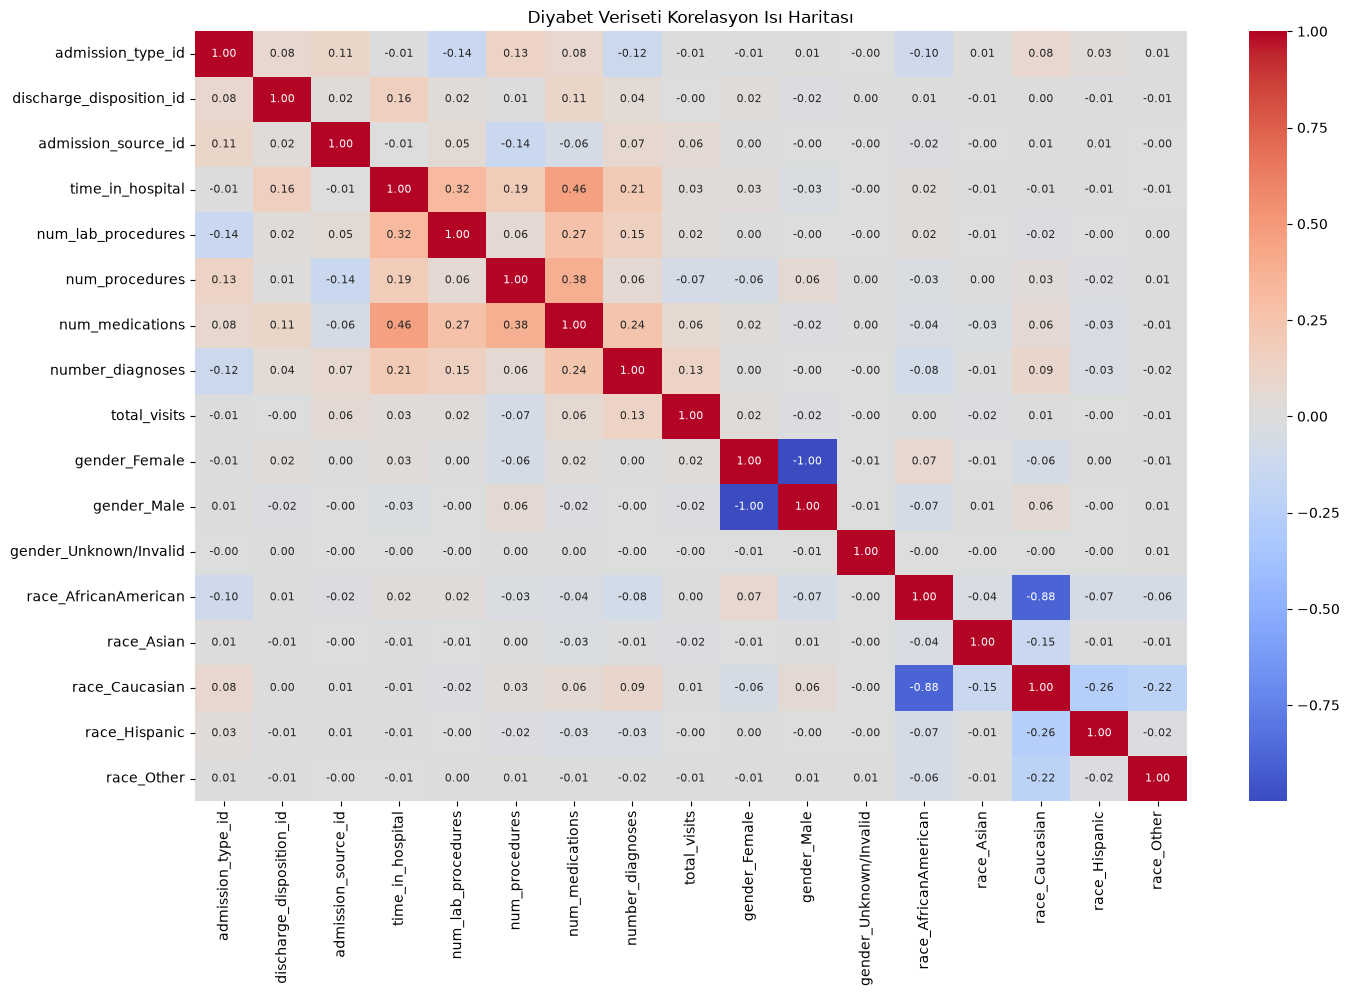

In [ ]:
plt.figure(figsize=(16, 10)) #Korelasyon haritası oluşturuldu.
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f", annot_kws={"size": 8})
plt.title("Diyabet Veriseti Korelasyon Isı Haritası")
plt.show()